# 两只股票的五模型最终测试

1. 在下方 `RUN_NAMES` 指定两个 `artifacts/` 下的实验目录名。
2. 股票、测试区间、特征、窗口和模型来源均读取保存的 JSON。
3. 选择 **EE6008** 内核，执行 **Restart Kernel → Run All**。修改目录后也需要从头运行。

方向定义始终为原始预测收益 `> 0` 表示上涨；真实收益为零归入“不涨”。排名仅描述已冻结模型的测试表现，不用于重新选参数。

In [1]:
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'main.py').is_file() and (p / 'src/evaluate.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('请从 stock_prediction 或 notebooks 目录打开此 Notebook')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import src.evaluate as evaluation
if Path(evaluation.__file__).resolve() != (ROOT / 'src/evaluate.py').resolve():
    raise RuntimeError('评价模块来自其他项目目录，请重启内核')

# 必填：两个测试实验目录名。不会自动查找最新目录，也不会退回其他实验。
RUN_NAMES = ['aapl_final_test_01', 'tsla_final_test_01']

# 只决定局部预测曲线显示最后多少个测试交易日。
# 它不是模型的历史输入窗口（window=60），不影响完整测试期指标。
RECENT_DAYS = 80
SHOW_RECENT_PREDICTIONS = True
SHOW_CONFUSION_MATRICES = True

MODELS = ['xgboost', 'lightgbm', 'patchtst', 'lstm', 'gru']
BASELINES = ['zero_return', 'historical_mean', 'last_return']
LABELS = dict(zip(MODELS + BASELINES,
    ['XGBoost', 'LightGBM', 'PatchTST', 'LSTM', 'GRU',
     'Zero return', 'Historical mean', 'Last return']))
COLORS = dict(zip(MODELS, ['#4477AA', '#EE9944', '#228866', '#AA4499', '#CC6677']))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('Python:', sys.executable)
print('Project:', ROOT)

Python: f:\Enviornment\miniforge3\envs\EE6008\python.exe
Project: f:\Singapore_study\EE6008\stock_prediction


## 1. 读取并核验两个指定的测试结果

仅接受完成的测试实验，要求记录为 `evaluation_split=test`、`test_evaluated=true`、`retrained=false`、`preprocessing_fitted=false`、`holdout_evaluated=false`。

检查包含：五模型及三基线是否完整、目标日期是否在测试区间、真实方向是否与收益一致、源实验及预处理记录是否一致，以及根据保存的逐日预测重算的指标是否与 `metrics.json` 相符。训练期多数方向基线也会重新核算测试准确率。

本页核验的是**结果文件内部一致性**；原数据和模型恢复核验由测试入口完成，其结果记录在 `validation_replay.json`。

In [2]:
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8-sig'))


def load_test_run(name):
    if not isinstance(name, str) or re.fullmatch(r'[A-Za-z0-9_-]+', name) is None:
        raise ValueError('请只填写 artifacts 下的实验目录名，不填写路径')
    folder = ROOT / 'artifacts' / name
    json_names = ['config', 'manifest', 'preprocessing', 'metrics', 'data_audit',
                  'direction_reference', 'source_manifest', 'validation_replay', 'inference']
    required = [f'{key}.json' for key in json_names] + ['predictions.csv']
    missing = [file for file in required if not (folder / file).is_file()]
    if missing:
        raise FileNotFoundError(f'{name} 缺少：{missing}')
    run = {key:read_json(folder / f'{key}.json') for key in json_names}
    run['name'] = name
    c, m, pre, audit = (run[key] for key in ['config','manifest','preprocessing','data_audit'])
    expected = {'status':'complete', 'evaluation_split':'test', 'test_evaluated':True,
                'retrained':False, 'preprocessing_fitted':False, 'holdout_evaluated':False}
    if any(m.get(key) != value for key,value in expected.items()):
        raise ValueError(f'{name}: 不是已完成、未重训且未使用保留期的测试实验')
    if not isinstance(c.get('ticker'), str) or not c['ticker'].strip():
        raise ValueError(f'{name}: config.json 缺少股票代码')
    if not set(MODELS).issubset(m.get('models_requested', [])):
        raise ValueError(f'{name}: manifest 缺少五模型记录')
    if m.get('seed') != c.get('seed') or not m.get('data_sha256'):
        raise ValueError(f'{name}: 随机种子或数据指纹记录错误')
    src = run['source_manifest']
    if (not m.get('source_run') or src.get('status') != 'complete'
            or src.get('evaluation_split') != 'validation'
            or src.get('data_sha256') != m['data_sha256']
            or src.get('seed') != c.get('seed')):
        raise ValueError(f'{name}: 模型来源记录不一致')
    if (run['inference'].get('source_run') != m['source_run']
            or run['inference'].get('retrained') is not False
            or not set(MODELS).issubset(run['inference'].get('models', {}))
            or run['validation_replay'].get('status') != 'passed'):
        raise ValueError(f'{name}: 推理来源或验证重现记录不一致')
    full = [prefix + f for prefix in ['', 'nasdaq_']
            for f in ['return','vol_change','intraday_return','range']]
    mode = c.get('nasdaq_features', 'all')
    if mode not in ['all','return_volume']:
        raise ValueError(f'{name}: 不支持的特征模式')
    features = full if mode == 'all' else full[:6]
    if (pre.get('features') != features or pre.get('window') != c.get('window')
            or audit.get('features') != features or audit.get('window') != c.get('window')):
        raise ValueError(f'{name}: 特征或窗口记录不一致')
    for key in ['feature_mean','feature_scale']:
        values = np.asarray(pre[key], dtype=float)
        if values.shape != (len(features),) or not np.isfinite(values).all():
            raise ValueError(f'{name}: 无效的保存预处理参数 {key}')
    if (not (np.asarray(pre['feature_scale']) > 0).all()
            or not np.isfinite([pre['target_mean'],pre['target_scale']]).all()
            or pre['target_scale'] <= 0):
        raise ValueError(f'{name}: 保存的缩放参数无效')
    lower, upper, holdout = map(pd.Timestamp, [c['validation_end'],c['test_end'],c['holdout_end']])
    if not lower < upper < holdout:
        raise ValueError(f'{name}: 测试期边界错误')
    if (audit.get('evaluation_split') != 'test' or audit.get('split_by') != 'target_date'
            or audit.get('read_cutoff') != str(upper.date())
            or audit.get('target_after') != str(lower.date())
            or audit.get('target_through') != str(upper.date())
            or audit.get('preprocessing_fitted') is not False
            or audit.get('holdout_evaluated') is not False):
        raise ValueError(f'{name}: 数据审计与测试区间不一致')
    pred = pd.read_csv(folder / 'predictions.csv', float_precision='round_trip')
    dates = ['window_start','signal_date','target_date']
    required_columns = dates + ['actual_return','actual_direction'] + MODELS + BASELINES
    if not set(required_columns).issubset(pred.columns):
        raise ValueError(f'{name}: 缺少日期、真实标签、模型或基线预测')
    for column in dates:
        pred[column] = pd.to_datetime(pred[column], errors='raise')
    if (len(pred) < 2 or pred[dates].isna().any().any()
            or pred.target_date.duplicated().any() or not pred.target_date.is_monotonic_increasing):
        raise ValueError(f'{name}: 日期缺失、重复、未排序或样本不足')
    if not ((pred.window_start <= pred.signal_date) & (pred.signal_date < pred.target_date)
            & (pred.target_date > lower) & (pred.target_date <= upper)).all():
        raise ValueError(f'{name}: 存在非因果窗口或测试区间之外的预测')
    if (len(pred) != audit.get('samples')
            or str(pred.target_date.min().date()) != audit.get('target_first')
            or str(pred.target_date.max().date()) != audit.get('target_last')):
        raise ValueError(f'{name}: 预测样本数或日期与审计不一致')
    np.testing.assert_array_equal(pred.actual_direction, (pred.actual_return > 0).astype(int))
    np.testing.assert_allclose(pred.zero_return, 0, rtol=0, atol=1e-12)
    np.testing.assert_allclose(pred.historical_mean, pre['target_mean'], rtol=0, atol=1e-12)
    metrics = {}
    for model in BASELINES + MODELS:
        if model not in run['metrics']:
            raise ValueError(f'{name}: metrics.json 缺少 {model}')
        metrics[model] = evaluation.evaluate(pred.actual_return.to_numpy(), pred[model].to_numpy())
        for key,value in metrics[model].items():
            saved = run['metrics'][model][key]
            if value is None or saved is None:
                if value != saved:
                    raise ValueError(f'{name}: {model}/{key} 指标不一致')
            else:
                np.testing.assert_allclose(value, saved, rtol=1e-8, atol=1e-12,
                    err_msg=f'{name}: {model}/{key} 与逐日预测不一致')
    ref = run['direction_reference']
    if not isinstance(ref.get('train_majority_up'), bool):
        raise ValueError(f'{name}: 训练期多数方向记录缺失')
    np.testing.assert_allclose(ref['test_accuracy'],
        np.mean((pred.actual_return > 0) == ref['train_majority_up']), rtol=0, atol=1e-12)
    run.update(ticker=c['ticker'], predictions=pred, metrics=metrics)
    return run


if not isinstance(RUN_NAMES, (list,tuple)) or len(RUN_NAMES) != 2 or len(set(RUN_NAMES)) != 2:
    raise ValueError('RUN_NAMES 必须指定两个不同的测试实验目录')
# 新一轮加载前清除旧汇总变量；出错时应修正目录并重新 Run All。
runs, summary, learned = [], None, None
loaded = [load_test_run(name) for name in RUN_NAMES]
if len({run['ticker'] for run in loaded}) != 2:
    raise ValueError('本页用于两只不同股票；同一股票前后实验应另作比较')
runs = loaded
metadata_rows = []
for run in runs:
    m,c,a = run['manifest'], run['config'], run['data_audit']
    metadata_rows.append({'stock':run['ticker'], 'test_run':run['name'], 'source_run':m['source_run'],
        'first_target':a['target_first'], 'last_target':a['target_last'], 'n':a['samples'],
        'features':len(run['preprocessing']['features']), 'window':c['window'], 'seed':c['seed'],
        'device':m.get('inference_device'), 'validation_replay':run['validation_replay']['status']})
display(pd.DataFrame(metadata_rows))
print('通过：两个实验均为完整测试结果；五模型及三基线的保存指标与逐日预测一致。')
if not runs[0]['predictions'].target_date.equals(runs[1]['predictions'].target_date):
    display(Markdown('**两只股票的测试日期不同：各自使用完整有效样本，不取交集，也不合并计算总指标。**'))

,stock,test_run,source_run,first_target,last_target,n,features,window,seed,device,validation_replay
0,AAPL,aapl_final_test_01,aapl_compare_all_01,2024-01-02,2025-12-31,502,8,60,42,cuda,passed
1,TSLA,tsla_final_test_01,tsla_compare_all_01,2024-01-02,2025-12-31,502,8,60,42,cuda,passed


通过：两个实验均为完整测试结果；五模型及三基线的保存指标与逐日预测一致。


## 2. 主要结果：方向准确率与基线差距

每只股票内按 **Direction accuracy 从高到低** 展示；同分并列，显示顺序沿用模型顺序。

| 列名 | 含义 |
|---|---|
| direction_accuracy | 完整测试期涨跌判断正确的比例，本页首要展示指标 |
| majority_accuracy | 训练期决定固定预测方向，再在本测试期评价的简单基线 |
| direction_gain_pp | 准确率减多数方向基线，以**百分点**表示；正数表示高于基线 |
| balanced_accuracy | 上涨召回率与不涨召回率的平均值，帮助识别类别偏向 |
| up_f1 | 上涨类精确率和召回率的调和平均，不代表对两类都预测得好 |
| predicted_up_rate / actual_up_rate | 预测与真实上涨比例，用于检查模型是否偏向猜涨 |


`summary` 保存五模型和三种收益基线；`learned` 只含五模型。

In [3]:
def direction_details(matrix):
    # 矩阵行/列顺序均为 [Not up, Up]。
    matrix = np.asarray(matrix, dtype=float)
    totals = matrix.sum(axis=1)
    recalls = np.divide(np.diag(matrix), totals,
                        out=np.full(2, np.nan), where=totals > 0)
    return {'not_up_recall': recalls[0],
            'balanced_accuracy': float(recalls.mean()) if (totals > 0).all() else np.nan}

records = []
majority_records = []
for run in runs:
    majority = run['direction_reference']['test_accuracy']
    for model in MODELS + BASELINES:
        metrics = run['metrics'][model]
        records.append({'stock': run['ticker'], 'model': model, 'run': run['name'],
            'kind': 'Model' if model in MODELS else 'Baseline',
            **{k: v for k, v in metrics.items() if k != 'confusion_matrix'},
            **direction_details(metrics['confusion_matrix']),
            'majority_accuracy': majority,
            'direction_gain_pp': 100 * (metrics['direction_accuracy'] - majority)})
    # 固定多数方向只评价分类，不为它虚构收益幅度或 RMSE。
    actual = run['predictions'].actual_return.to_numpy() > 0
    predicted = np.full(actual.shape, run['direction_reference']['train_majority_up'], dtype=bool)
    matrix = np.array([[np.sum(~actual & ~predicted), np.sum(~actual & predicted)],
                       [np.sum(actual & ~predicted), np.sum(actual & predicted)]])
    tp, fp, fn = matrix[1,1], matrix[0,1], matrix[1,0]
    majority_records.append({'stock': run['ticker'], 'model': 'train_majority', 'kind': 'Direction baseline',
        'n': len(actual), 'direction_accuracy': majority, 'majority_accuracy': majority,
        'direction_gain_pp': 0.0, **direction_details(matrix),
        'up_precision': tp/(tp+fp) if tp+fp else 0.0,
        'up_recall': tp/(tp+fn) if tp+fn else 0.0,
        'up_f1': 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.0,
        'actual_up_rate': actual.mean(), 'predicted_up_rate': predicted.mean()})
summary = pd.DataFrame(records)
learned = summary[summary.model.isin(MODELS)].copy()
majority_summary = pd.DataFrame(majority_records)
LABELS['train_majority'] = 'Train-majority direction'
main_columns = ['n', 'direction_accuracy', 'majority_accuracy', 'direction_gain_pp',
                'balanced_accuracy', 'up_f1', 'predicted_up_rate', 'actual_up_rate']
formats = {k: '{:.2%}' for k in ['direction_accuracy', 'majority_accuracy', 'balanced_accuracy',
           'predicted_up_rate', 'actual_up_rate', 'up_precision', 'up_recall', 'not_up_recall']}
formats.update(n='{:d}', direction_gain_pp='{:+.2f}', up_f1='{:.4f}')
for run in runs:
    data = learned[learned.stock == run['ticker']].sort_values('direction_accuracy', ascending=False, kind='stable').copy()
    data['rank'] = data.direction_accuracy.rank(method='min', ascending=False).astype(int)
    display(Markdown(f"### {run['ticker']} · direction first"))
    view = data.assign(model=data.model.map(LABELS)).set_index('model')[['rank', *main_columns]]
    display(view.style.format(formats | {'rank': '{:d}'}, na_rep='N/A'))

### AAPL · direction first

,rank,n,direction_accuracy,majority_accuracy,direction_gain_pp,balanced_accuracy,up_f1,predicted_up_rate,actual_up_rate
model,,,,,,,,,
LSTM,1,502,54.38%,54.38%,+0.00,50.00%,0.7045,100.00%,54.38%
LightGBM,2,502,54.18%,54.38%,-0.20,50.13%,0.6958,96.22%,54.38%
GRU,3,502,53.19%,54.38%,-1.20,49.08%,0.6904,96.81%,54.38%
XGBoost,4,502,52.79%,54.38%,-1.59,49.27%,0.6731,90.04%,54.38%
PatchTST,5,502,49.60%,54.38%,-4.78,48.70%,0.5600,60.16%,54.38%


### TSLA · direction first

,rank,n,direction_accuracy,majority_accuracy,direction_gain_pp,balanced_accuracy,up_f1,predicted_up_rate,actual_up_rate
model,,,,,,,,,
GRU,1,502,51.39%,50.40%,+1.00,51.02%,0.6703,97.01%,50.40%
XGBoost,2,502,50.60%,50.40%,+0.20,50.35%,0.6242,81.08%,50.40%
LSTM,3,502,50.40%,50.40%,+0.00,50.00%,0.6702,100.00%,50.40%
LightGBM,4,502,50.20%,50.40%,-0.20,49.84%,0.6575,95.02%,50.40%
PatchTST,5,502,47.61%,50.40%,-2.79,47.67%,0.4368,42.63%,50.40%


## 3. 核心图表：准确率、基线以上提升和两类平衡表现

每行一只股票，模型颜色固定。左图显示方向准确率和训练期多数方向基线；中图显示相对基线的百分点差距，正数更好；右图显示平衡准确率，50% 是两类均存在时固定猜一个方向的参照。

准确率和平衡准确率采用统一的 0—100% 纵轴；中图两只股票使用相同的对称范围。

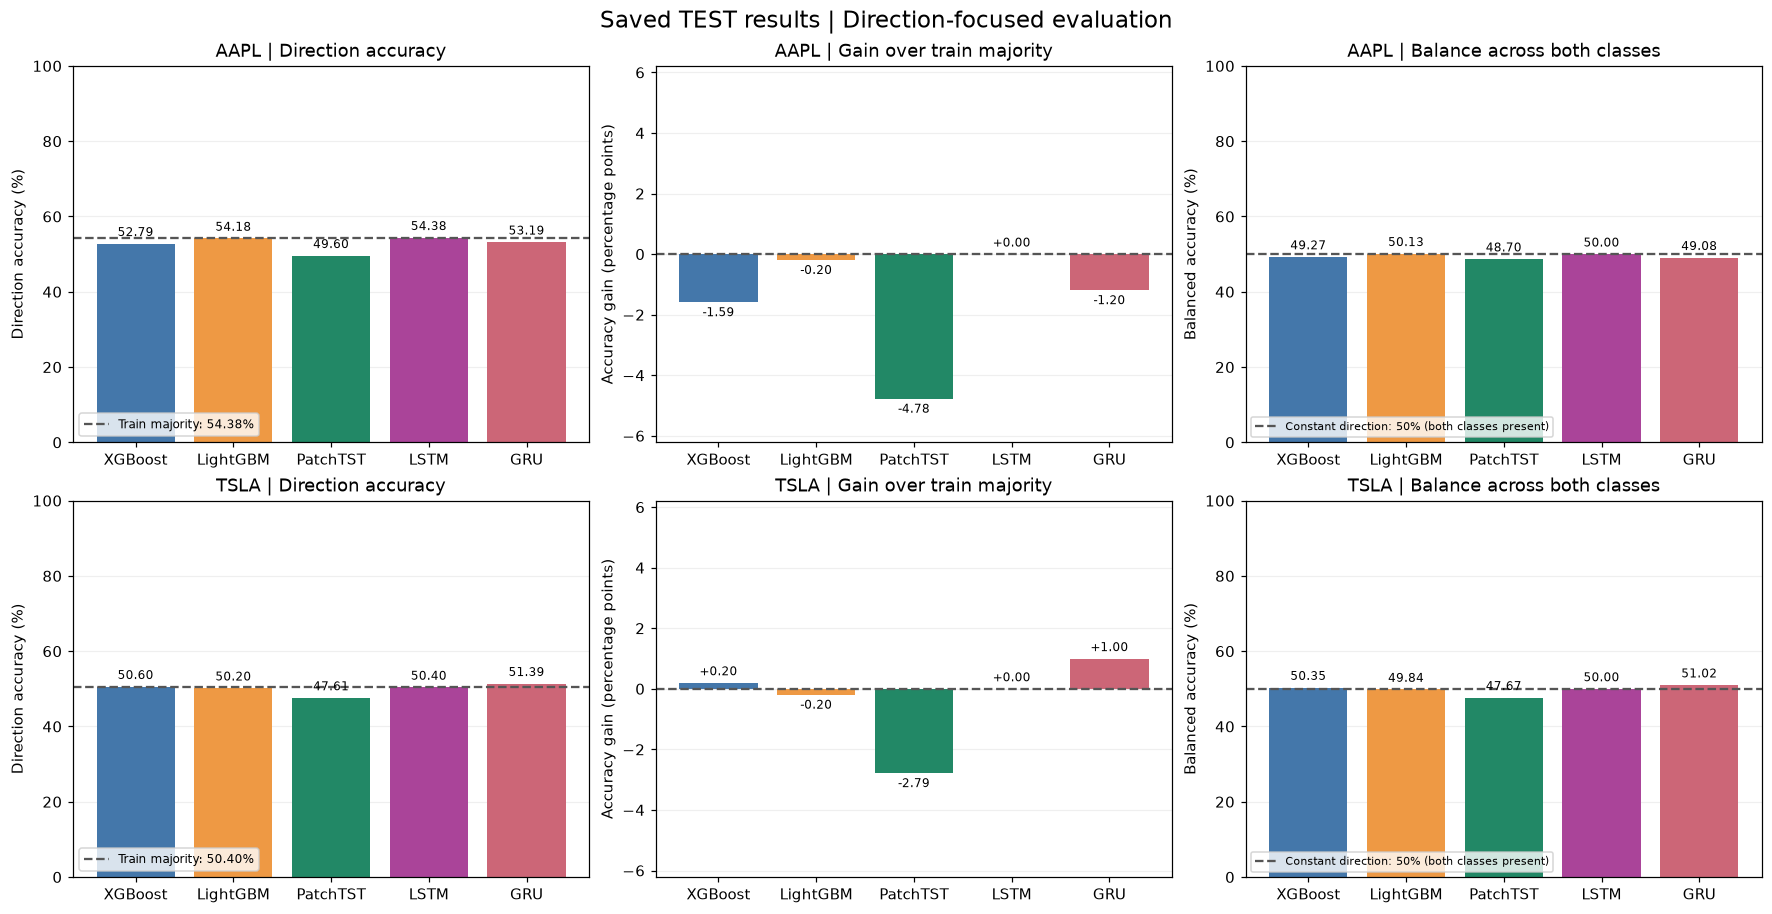

In [4]:
fig, axes = plt.subplots(len(runs), 3, figsize=(16, 4.1*len(runs)), squeeze=False, layout='constrained')
gain_limit = max(1.0, float(learned.direction_gain_pp.abs().max()) * 1.3)
for i, run in enumerate(runs):
    data = learned[learned.stock == run['ticker']].set_index('model').loc[MODELS]
    names, colors = [LABELS[m] for m in MODELS], [COLORS[m] for m in MODELS]
    ax = axes[i,0]
    bars = ax.bar(names, data.direction_accuracy*100, color=colors)
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=8)
    ref = run['direction_reference']['test_accuracy']*100
    ax.axhline(ref, color='#555555', ls='--', label=f'Train majority: {ref:.2f}%')
    ax.set(ylim=(0,100), ylabel='Direction accuracy (%)', title=f"{run['ticker']} | Direction accuracy")
    ax.legend(fontsize=8, loc='lower left')
    ax = axes[i,1]
    bars = ax.bar(names, data.direction_gain_pp, color=colors)
    ax.bar_label(bars, fmt='%+.2f', padding=3, fontsize=8)
    ax.axhline(0, color='#555555', ls='--')
    ax.set(ylim=(-gain_limit,gain_limit), ylabel='Accuracy gain (percentage points)',
           title=f"{run['ticker']} | Gain over train majority")
    ax = axes[i,2]
    bars = ax.bar(names, data.balanced_accuracy*100, color=colors)
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=8)
    ax.axhline(50, color='#555555', ls='--', label='Constant direction: 50% (both classes present)')
    ax.set(ylim=(0,100), ylabel='Balanced accuracy (%)', title=f"{run['ticker']} | Balance across both classes")
    ax.legend(fontsize=7, loc='lower left')
    for ax in axes[i]:
        ax.grid(axis='y', alpha=.2)
        ax.set_axisbelow(True)
fig.suptitle('Saved TEST results | Direction-focused evaluation', fontsize=15)
plt.show()
plt.close(fig)

## 4. 完整方向排名：五模型、三种收益基线与固定多数方向

按方向准确率降序排列，同分同名次。三个收益基线仍按其预测收益的正负号评价：零收益基线始终预测“不涨”，历史均值基线的方向由训练均值正负决定。

另列 `Train-majority direction`，它直接使用训练期多数类别；可能与历史均值基线产生完全相同的方向预测，但两者定义不同。`not_up_recall` 是实际不涨日判断正确的比例；与 `up_recall` 一起看，避免仅凭上涨 F1 判断整体效果。

In [5]:
direction_columns = ['rank', 'kind', *main_columns, 'up_precision', 'up_recall', 'not_up_recall']
for run in runs:
    display(Markdown(f"### {run['ticker']} · {run['name']}"))
    ranking = pd.concat([summary[summary.stock == run['ticker']],
                         majority_summary[majority_summary.stock == run['ticker']]], ignore_index=True)
    ranking = ranking.sort_values('direction_accuracy', ascending=False, kind='stable')
    ranking['rank'] = ranking.direction_accuracy.rank(method='min', ascending=False).astype(int)
    ranking['model'] = ranking.model.map(LABELS)
    display(ranking.set_index('model')[direction_columns].style.format(
        formats | {'rank': '{:d}'}, na_rep='N/A'))

### AAPL · aapl_final_test_01

,rank,kind,n,direction_accuracy,majority_accuracy,direction_gain_pp,balanced_accuracy,up_f1,predicted_up_rate,actual_up_rate,up_precision,up_recall,not_up_recall
model,,,,,,,,,,,,,
LSTM,1,Model,502,54.38%,54.38%,+0.00,50.00%,0.7045,100.00%,54.38%,54.38%,100.00%,0.00%
Historical mean,1,Baseline,502,54.38%,54.38%,+0.00,50.00%,0.7045,100.00%,54.38%,54.38%,100.00%,0.00%
Train-majority direction,1,Direction baseline,502,54.38%,54.38%,+0.00,50.00%,0.7045,100.00%,54.38%,54.38%,100.00%,0.00%
LightGBM,4,Model,502,54.18%,54.38%,-0.20,50.13%,0.6958,96.22%,54.38%,54.45%,96.34%,3.93%
GRU,5,Model,502,53.19%,54.38%,-1.20,49.08%,0.6904,96.81%,54.38%,53.91%,95.97%,2.18%
XGBoost,6,Model,502,52.79%,54.38%,-1.59,49.27%,0.6731,90.04%,54.38%,53.98%,89.38%,9.17%
Last return,7,Baseline,502,52.59%,54.38%,-1.79,52.22%,0.5641,54.38%,54.38%,56.41%,56.41%,48.03%
PatchTST,8,Model,502,49.60%,54.38%,-4.78,48.70%,0.5600,60.16%,54.38%,53.31%,58.97%,38.43%
Zero return,9,Baseline,502,45.62%,54.38%,-8.76,50.00%,0.0000,0.00%,54.38%,0.00%,0.00%,100.00%


### TSLA · tsla_final_test_01

,rank,kind,n,direction_accuracy,majority_accuracy,direction_gain_pp,balanced_accuracy,up_f1,predicted_up_rate,actual_up_rate,up_precision,up_recall,not_up_recall
model,,,,,,,,,,,,,
GRU,1,Model,502,51.39%,50.40%,+1.00,51.02%,0.6703,97.01%,50.40%,50.92%,98.02%,4.02%
XGBoost,2,Model,502,50.60%,50.40%,+0.20,50.35%,0.6242,81.08%,50.40%,50.61%,81.42%,19.28%
LSTM,3,Model,502,50.40%,50.40%,+0.00,50.00%,0.6702,100.00%,50.40%,50.40%,100.00%,0.00%
Historical mean,3,Baseline,502,50.40%,50.40%,+0.00,50.00%,0.6702,100.00%,50.40%,50.40%,100.00%,0.00%
Train-majority direction,3,Direction baseline,502,50.40%,50.40%,+0.00,50.00%,0.6702,100.00%,50.40%,50.40%,100.00%,0.00%
LightGBM,6,Model,502,50.20%,50.40%,-0.20,49.84%,0.6575,95.02%,50.40%,50.31%,94.86%,4.82%
Zero return,7,Baseline,502,49.60%,50.40%,-0.80,50.00%,0.0000,0.00%,50.40%,0.00%,0.00%,100.00%
Last return,8,Baseline,502,49.00%,50.40%,-1.39,49.00%,0.4941,50.40%,50.40%,49.41%,49.41%,48.59%
PatchTST,9,Model,502,47.61%,50.40%,-2.79,47.67%,0.4368,42.63%,50.40%,47.66%,40.32%,55.02%


## 5. 涨跌混淆矩阵（可选）

行是真实类别、列是预测类别，顺序均为 `[不涨, 上涨]`。数字是样本数，括号内为该真实类别中的比例，颜色也按行归一化。图中 `Not up` 包含下跌及平盘。
这些矩阵帮助判断模型是否偏向一直预测上涨。

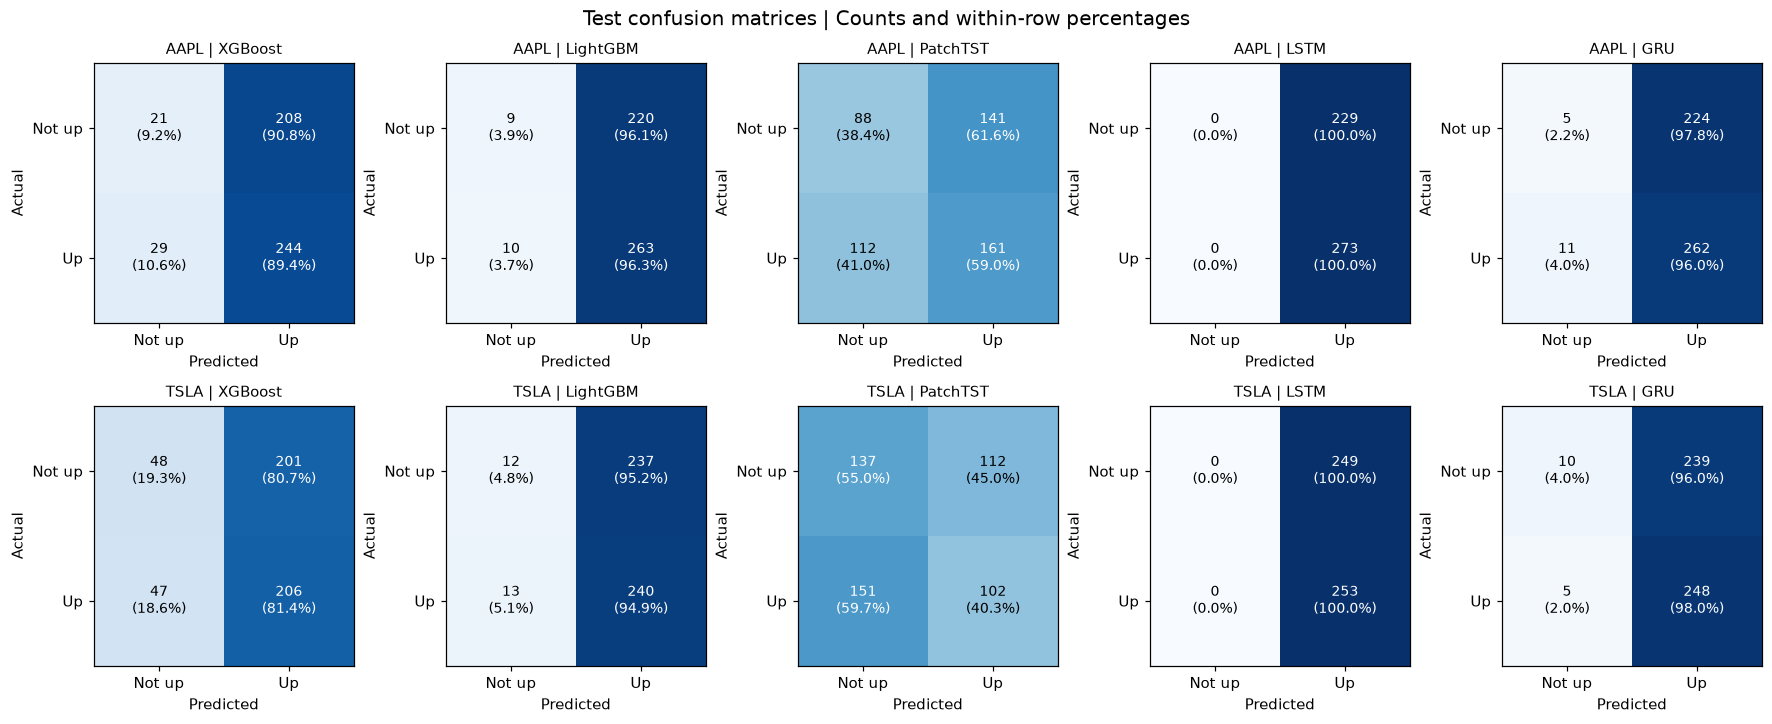

In [6]:
if SHOW_CONFUSION_MATRICES:
    fig, axes = plt.subplots(len(runs), len(MODELS), figsize=(16, 6.5), squeeze=False, layout='constrained')
    for i, run in enumerate(runs):
        for j, model in enumerate(MODELS):
            ax = axes[i,j]
            matrix = np.asarray(run['metrics'][model]['confusion_matrix'])
            totals = matrix.sum(axis=1, keepdims=True)
            rates = np.divide(matrix, totals, out=np.zeros_like(matrix, dtype=float), where=totals!=0)
            ax.imshow(rates, cmap='Blues', vmin=0, vmax=1)
            for row in range(2):
                for column in range(2):
                    text = f'{matrix[row,column]}' + chr(10) + f'({rates[row,column]:.1%})'
                    ax.text(column, row, text, ha='center', va='center', fontsize=9,
                            color='white' if rates[row,column]>.55 else 'black')
            ax.set_xticks([0,1], ['Not up','Up'])
            ax.set_yticks([0,1], ['Not up','Up'])
            ax.set_xlabel('Predicted')
            ax.set_ylabel('Actual')
            ax.set_title(f"{run['ticker']} | {LABELS[model]}", fontsize=10)
    fig.suptitle('Test confusion matrices | Counts and within-row percentages', fontsize=13)
    plt.show()
    plt.close(fig)
else:
    print('已跳过混淆矩阵图；方向指标仍在上表展示。')

## 6. 方向为先的自动小结

自动报告最高方向准确率（保留并列）、与固定多数方向基线的百分点差距、超过基线的模型，以及预测上涨倾向。

In [10]:
for run in runs:
    data = learned[learned.stock == run['ticker']].copy()
    best_accuracy = data.direction_accuracy.max()
    winners = data[np.isclose(data.direction_accuracy, best_accuracy, rtol=0, atol=1e-12)]
    majority = run['direction_reference']['test_accuracy']
    above = data[data.direction_accuracy > majority + 1e-12].sort_values('direction_accuracy', ascending=False)
    fixed_label = '上涨' if run['direction_reference']['train_majority_up'] else '不涨'
    lines = [f"### {run['ticker']}", '',
        f"- 测试目录：`{run['name']}`；模型来源：`{run['manifest']['source_run']}`。",
        f"- 测试期：{run['data_audit']['target_first']} 至 {run['data_audit']['target_last']}，共 {len(run['predictions'])} 日。",
        f"- 五模型方向准确率最高：**{'、'.join(LABELS[m] for m in winners.model)}**，**{best_accuracy:.2%}**。",
        f"- 训练期多数方向为“{fixed_label}”，固定预测该方向的测试准确率为 {majority:.2%}；领先模型相对它为 **{(best_accuracy-majority)*100:+.2f} 个百分点**。",
        '- 方向准确率高于多数方向基线的模型：' + ('、'.join(LABELS[m] for m in above.model) if len(above) else '无') + '。']
    for row in winners.itertuples():
        balanced = f'{row.balanced_accuracy:.2%}' if np.isfinite(row.balanced_accuracy) else 'N/A（缺少一个真实类别）'
        lines.append(f'- {LABELS[row.model]}：平衡准确率 {balanced}，上涨 F1={row.up_f1:.4f}；预测上涨比例 {row.predicted_up_rate:.2%}，真实上涨比例 {row.actual_up_rate:.2%}。')
    lines.append('- 方向排名不代表收益幅度排名；误差指标见下方补充。')
    display(Markdown(chr(10).join(lines)))
display(Markdown('**上述排名只描述保存的测试结果**'))

### AAPL

- 测试目录：`aapl_final_test_01`；模型来源：`aapl_compare_all_01`。
- 测试期：2024-01-02 至 2025-12-31，共 502 日。
- 五模型方向准确率最高：**LSTM**，**54.38%**。
- 训练期多数方向为“上涨”，固定预测该方向的测试准确率为 54.38%；领先模型相对它为 **+0.00 个百分点**。
- 方向准确率高于多数方向基线的模型：无。
- LSTM：平衡准确率 50.00%，上涨 F1=0.7045；预测上涨比例 100.00%，真实上涨比例 54.38%。
- 方向排名不代表收益幅度排名；误差指标见下方补充。

### TSLA

- 测试目录：`tsla_final_test_01`；模型来源：`tsla_compare_all_01`。
- 测试期：2024-01-02 至 2025-12-31，共 502 日。
- 五模型方向准确率最高：**GRU**，**51.39%**。
- 训练期多数方向为“上涨”，固定预测该方向的测试准确率为 50.40%；领先模型相对它为 **+1.00 个百分点**。
- 方向准确率高于多数方向基线的模型：GRU、XGBoost。
- GRU：平衡准确率 51.02%，上涨 F1=0.6703；预测上涨比例 97.01%，真实上涨比例 50.40%。
- 方向排名不代表收益幅度排名；误差指标见下方补充。

**上述排名只描述保存的测试结果**

## 7. 补充：收益幅度误差

方向猜对不意味着收益幅度准确，所以保留原回归指标供补充阅读。MAE、RMSE 越低越好；表中为小数收益，0.01 对应 1 个百分点。R² 与 R² vs zero 越高越好，后者大于零才表示平方误差低于零收益预测。


### AAPL · supplementary return metrics

,kind,n,direction_accuracy,mae,rmse,r2,r2_vs_zero
model,,,,,,,
LSTM,Model,502,54.38%,0.011561,0.017596,0.000938,0.003213
Historical mean,Baseline,502,54.38%,0.011559,0.017608,-0.000389,0.001889
LightGBM,Model,502,54.18%,0.011547,0.017636,-0.003607,-0.001322
GRU,Model,502,53.19%,0.011576,0.017587,0.001918,0.004190
XGBoost,Model,502,52.79%,0.011692,0.017745,-0.016095,-0.013782
Last return,Baseline,502,52.59%,0.015930,0.024307,-0.906377,-0.902036
PatchTST,Model,502,49.60%,0.012626,0.018375,-0.089494,-0.087013
Zero return,Baseline,502,45.62%,0.011609,0.017624,-0.002282,0.000000


### TSLA · supplementary return metrics

,kind,n,direction_accuracy,mae,rmse,r2,r2_vs_zero
model,,,,,,,
GRU,Model,502,51.39%,0.028980,0.039989,-0.003272,-0.000839
XGBoost,Model,502,50.60%,0.028951,0.039920,0.000165,0.002589
LSTM,Model,502,50.40%,0.028938,0.039948,-0.001242,0.001186
Historical mean,Baseline,502,50.40%,0.028946,0.039928,-0.000240,0.002185
LightGBM,Model,502,50.20%,0.029046,0.040008,-0.004248,-0.001813
Zero return,Baseline,502,49.60%,0.028874,0.039972,-0.002431,0.000000
Last return,Baseline,502,49.00%,0.042105,0.056904,-1.031572,-1.026645
PatchTST,Model,502,47.61%,0.030629,0.041632,-0.087440,-0.084803


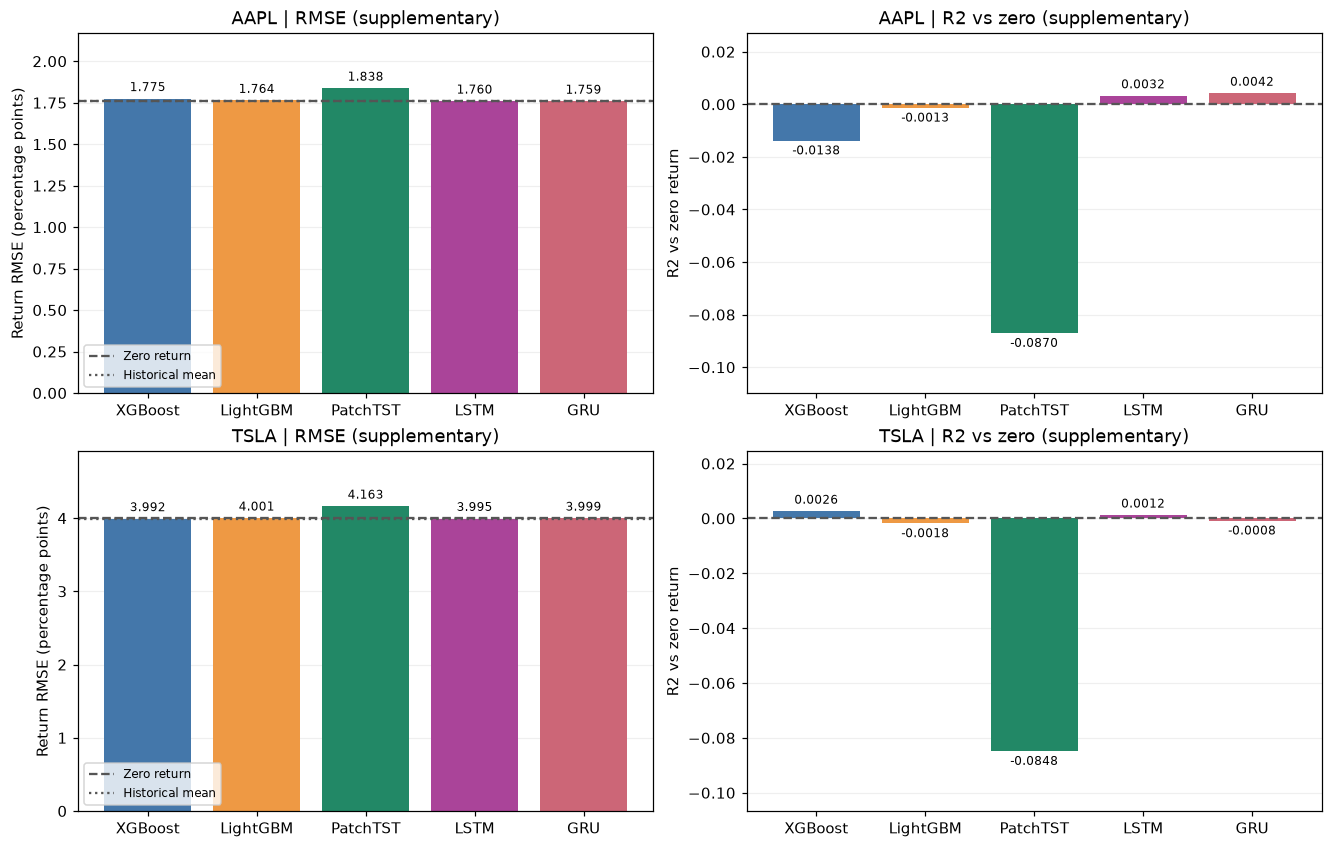

In [11]:
regression_columns = ['kind', 'n', 'direction_accuracy', 'mae', 'rmse', 'r2', 'r2_vs_zero']
regression_formats = formats | {k: '{:.6f}' for k in ['mae', 'rmse', 'r2', 'r2_vs_zero']}
for run in runs:
    display(Markdown(f"### {run['ticker']} · supplementary return metrics"))
    table = summary[summary.stock == run['ticker']].sort_values('direction_accuracy', ascending=False, kind='stable')
    display(table.assign(model=table.model.map(LABELS)).set_index('model')[regression_columns]
            .style.format(regression_formats, na_rep='N/A'))
fig, axes = plt.subplots(len(runs), 2, figsize=(12, 3.8*len(runs)), squeeze=False, layout='constrained')
for i, run in enumerate(runs):
    data = learned[learned.stock == run['ticker']].set_index('model').loc[MODELS]
    names, colors = [LABELS[m] for m in MODELS], [COLORS[m] for m in MODELS]
    ax = axes[i,0]
    bars = ax.bar(names, data.rmse*100, color=colors)
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
    for baseline, style in [('zero_return','--'), ('historical_mean',':')]:
        ax.axhline(run['metrics'][baseline]['rmse']*100, color='#555555', ls=style, label=LABELS[baseline])
    ax.set(title=f"{run['ticker']} | RMSE (supplementary)", ylabel='Return RMSE (percentage points)')
    ax.margins(y=.18)
    ax.legend(fontsize=8, loc='lower left')
    ax = axes[i,1]
    bars = ax.bar(names, data.r2_vs_zero, color=colors)
    ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=8)
    ax.axhline(0, color='#555555', ls='--')
    ax.set(title=f"{run['ticker']} | R2 vs zero (supplementary)", ylabel='R2 vs zero return')
    ax.margins(y=.25)
    for ax in axes[i]:
        ax.grid(axis='y', alpha=.2)
        ax.set_axisbelow(True)
plt.show()
plt.close(fig)

## 8. 补充：五模型收益预测曲线（可选）

灰色是真实收益，彩色是模型预测。每一行对应一个模型，每一列对应一只股票。


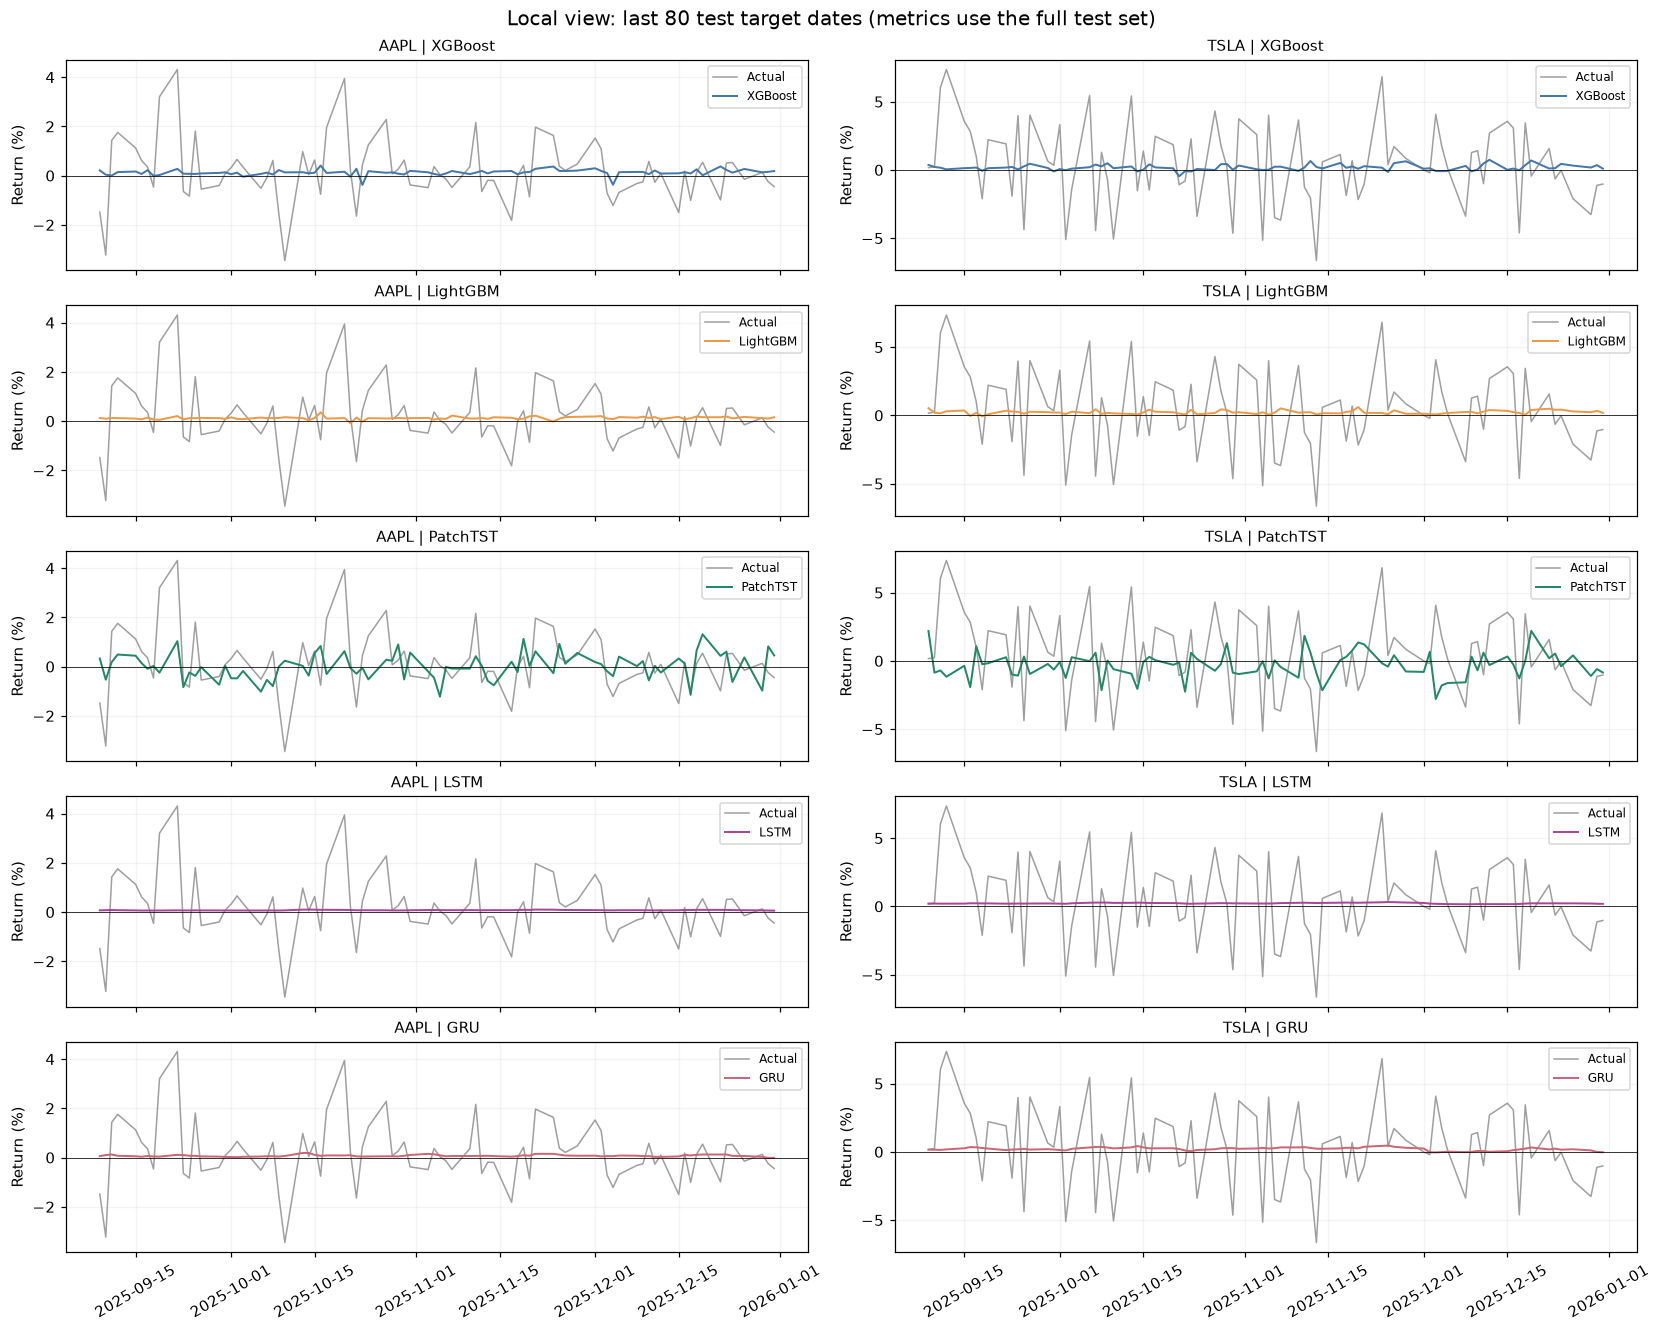

In [12]:
if SHOW_RECENT_PREDICTIONS:
    if not isinstance(RECENT_DAYS, int) or isinstance(RECENT_DAYS, bool) or RECENT_DAYS < 1:
        raise ValueError('RECENT_DAYS 必须为正整数')
    fig, axes = plt.subplots(len(MODELS), len(runs), figsize=(15, 12), squeeze=False,
                             sharex='col', sharey='col', layout='constrained')
    for j, run in enumerate(runs):
        recent = run['predictions'].tail(RECENT_DAYS)
        for i, model in enumerate(MODELS):
            ax = axes[i,j]
            ax.plot(recent.target_date, recent.actual_return*100, color='#777777', lw=1, alpha=.7, label='Actual')
            ax.plot(recent.target_date, recent[model]*100, color=COLORS[model], lw=1.3, label=LABELS[model])
            ax.axhline(0, color='black', lw=.5)
            ax.set_title(f"{run['ticker']} | {LABELS[model]}", fontsize=10)
            ax.set_ylabel('Return (%)')
            ax.grid(alpha=.15)
            ax.legend(fontsize=8, loc='upper right')
        axes[-1,j].tick_params(axis='x', labelrotation=30)
    fig.suptitle(f'Local view: last {RECENT_DAYS} test target dates (metrics use the full test set)', fontsize=13)
    plt.show()
    plt.close(fig)
else:
    print('已跳过局部预测曲线；完整测试期指标不受影响。')